# Logistic Regression — Job Change Intentions

## Chapter 0 — Storyline and analytical process

Wir modellieren, ob eine Person **aktuell nach einem neuen Job sucht** (`job_change=1`),
nicht ob sie später tatsächlich den Job wechselt. Die Grundlage sind eure beiden PKL-Dateien.
Eine Zeile entspricht einer Person; zehn ursprüngliche Eingabemerkmale werden verwendet.

**Ablauf:** 1. Warum LogReg? → 2. Score und Sigmoid → 3. Lernen mit BCE/MLE →
4. fünf Validierungsfolds → 5. Confusion Matrix → 6. Precision/Recall/F1 →
7. ROC/AUC → 8. kostenbasierte Entscheidung und Fazit.

**Start:** Notebook im Datenordner öffnen, passenden Python-Kernel wählen und **Restart & Run All**.
Benötigt werden NumPy, pandas, SciPy, scikit-learn, Matplotlib und IPython
(getestete Umgebung: scikit-learn 1.7.1). Acht Grafiken werden mit 300 dpi unter `figures/` gespeichert.
Alle Plots sind Englisch; die kurzen Erklärungen sind Deutsch. Es werden keine Slides erzeugt.

Wir nutzen **ein festes Basismodell (C=1)** ohne Parametersuche. Die empirische Kostenschwelle wird in Kapitel 4
auf Trainings-OOF-Prognosen festgelegt, bevor Testprognosen ausgewertet werden; Kapitel 8 erklärt diese Entscheidung.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.special import expit
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, log_loss, roc_curve)

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
BLUE, ORANGE, GRAY = '#2463A6', '#D87828', '#6B7280'
plt.rcParams.update({'figure.figsize': (8, 4.6), 'font.size': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 15, 'axes.labelsize': 12, 'legend.fontsize': 10,
    'figure.facecolor': 'white', 'axes.facecolor': 'white'})

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

### Bestehendes Preprocessing — unverändert

Die folgenden zwei Zellen übernehmen die Spaltengruppen und `make_preprocessor` wortgleich aus dem bisherigen
Notebook. Die Datenbereinigung bleibt ebenfalls identisch und ist nur als `prepare_data` gekapselt.
Numerische und ordinale Merkmale werden standardisiert; binäre und One-Hot-Spalten bleiben wie bisher unskaliert.
`student_id`, `city` und das Target sind keine Eingabemerkmale. Bereits in den PKL-Dateien erfolgte Aufbereitung
wird nicht rückgängig gemacht. Diesen technischen Block kann man beim Präsentieren überspringen.

In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report


# 1. Spaltengruppen festlegen
numeric_cols = ["city_development_index", "training_hours"]

# Diese Spalte muss bereits als 0/1 codiert sein.
binary_cols = ["relevant_experience"]

# Kategorien mit natürlicher Reihenfolge: niedrig nach hoch
ordinal_order = {
    "education_level": [
        "Primary School", "High School", "Graduate", "Masters", "Phd"
    ],
    "experience": ["<1"] + [str(i) for i in range(1, 21)] + [">20"],
    "last_new_job": ["never", "1", "2", "3", "4", ">4"],
}
ordinal_cols = list(ordinal_order)

nominal_cols = [
    "enrolled_university",
    "major_discipline",
    "company_size",
    "company_type",
]


# 2. Vorverarbeitung definieren
def make_preprocessor(
    encoding="gemischt",
    scaler_class=StandardScaler,
    scale=True,
    exclude=()
):
    if encoding not in {"gemischt", "one-hot"}:
        raise ValueError("encoding muss 'gemischt' oder 'one-hot' sein.")

    def keep(cols):
        return [column for column in cols if column not in exclude]

    num = keep(numeric_cols)
    binary = keep(binary_cols)
    ord_cols = keep(ordinal_cols)
    nom = keep(nominal_cols)

    def make_scaler():
        return scaler_class() if scale else "passthrough"

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", make_scaler()),
    ])

    binary_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ])

    nominal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )),
    ])

    if encoding == "one-hot":
        return ColumnTransformer([
            ("num", numeric_pipeline, num),
            ("bin", binary_pipeline, binary),
            ("cat", nominal_pipeline, ord_cols + nom),
        ])

    ordinal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            categories=[ordinal_order[column] for column in ord_cols],
            handle_unknown="use_encoded_value",
            unknown_value=-1,
        )),
        ("scaler", make_scaler()),
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, num),
        ("bin", binary_pipeline, binary),
        ("ord", ordinal_pipeline, ord_cols),
        ("nom", nominal_pipeline, nom),
    ])




In [3]:
def prepare_data(df):
    df = df.dropna(subset=["job_change"]).copy()

    X = df.drop(columns=["job_change", "student_id"], errors="ignore").copy()
    y = pd.to_numeric(df["job_change"], errors="raise")

    if set(y.unique()) != {0, 1}:
        raise ValueError("job_change muss die beiden Klassen 0 und 1 enthalten.")

    y = y.astype(int)


    # 4. Benötigte Spalten und Datentypen prüfen
    required_columns = numeric_cols + binary_cols + ordinal_cols + nominal_cols
    missing_columns = [
        column for column in required_columns if column not in X.columns
    ]

    if missing_columns:
        raise ValueError(f"Diese Spalten fehlen: {missing_columns}")

    # Nur die festgelegten Merkmale verwenden.
    X = X[required_columns].copy()

    for column in numeric_cols + binary_cols:
        X[column] = pd.to_numeric(X[column], errors="raise").astype(float)

    if not X["relevant_experience"].dropna().isin([0, 1]).all():
        raise ValueError("relevant_experience muss als 0/1 codiert sein.")


    # Kategorien einheitlich als Text darstellen.
    # Bei experience und last_new_job wird z. B. 1.0 zu "1".
    def category_to_text(value, normalize_integer=False):
        if pd.isna(value):
            return np.nan

        text = str(value).strip()

        if normalize_integer:
            try:
                number = float(text)
                if np.isfinite(number) and number.is_integer():
                    return str(int(number))
            except ValueError:
                pass

        return text


    for column in ordinal_cols + nominal_cols:
        normalize_integer = column in ["experience", "last_new_job"]
        X[column] = X[column].map(
            lambda value: category_to_text(value, normalize_integer)
        ).astype(object)
    return X, y


In [4]:
train_data = pd.read_pickle('customer_train_final_train.pkl')
test_data = pd.read_pickle('customer_train_final_test.pkl')
if 'job_change' not in test_data or test_data['job_change'].isna().all():
    raise ValueError('Test labels are unavailable: test metrics cannot be calculated. No results are fabricated.')
X_train, y_train = prepare_data(train_data)
X_test, y_test = prepare_data(test_data)
assert train_data.student_id.is_unique and test_data.student_id.is_unique
assert set(train_data.student_id).isdisjoint(set(test_data.student_id))
assert not X_train.isna().all().any()
assert list(X_train.columns) == list(X_test.columns)

feature_overview = pd.DataFrame({
    'Original type': train_data[X_train.columns].dtypes.astype(str),
    'Missing (train)': train_data[X_train.columns].isna().sum(),
    'Missing (test)': test_data[X_train.columns].isna().sum(),
})
display(feature_overview)
display(pd.DataFrame({'Training': y_train.value_counts(), 'Test': y_test.value_counts()})
        .rename_axis('job_change').sort_index())
print(f'Training: {len(y_train):,} | Test: {len(y_test):,} | Input features: {X_train.shape[1]}')
print(f'Positive labels in training: {y_train.mean():.1%}')

,Original type,Missing (train),Missing (test)
city_development_index,float64,0,0
training_hours,int32,0,0
relevant_experience,bool,0,0
education_level,category,0,0
experience,category,0,0
last_new_job,category,0,0
enrolled_university,category,0,0
major_discipline,category,0,0
company_size,category,0,0
company_type,category,0,0


,Training,Test
job_change,,
0,11504,2877
1,3822,955


Training: 15,326 | Test: 3,832 | Input features: 10
Positive labels in training: 24.9%


Die Eingaben beschreiben Stadtentwicklungsindex, Trainingsstunden, relevante Erfahrung, Hochschulstatus,
Bildungsabschluss, Fachrichtung, Berufserfahrung, Unternehmensgröße/-typ und Zeit seit dem letzten Jobwechsel.
In den gelieferten Dateien fehlen keine Werte; die bisherigen Imputer bleiben trotzdem Bestandteil der Pipeline.
Die positive Klasse ist die kleinere Klasse. Alle Merkmale müssen zum geplanten Entscheidungszeitpunkt bekannt sein,
insbesondere `training_hours` — hier nehmen wir eine Entscheidung nach ihrer Erfassung an.

## Chapter 1 — Why logistic instead of linear regression?

Das Ziel hat nur die Werte 0 und 1. Eine gewöhnliche lineare Regression liefert eine unbeschränkte Gerade:
Sie kann Werte unter 0 oder über 1 vorhersagen, die keine gültigen Wahrscheinlichkeiten sind.
Die logistische Regression begrenzt ihre Ausgabe durch die Sigmoid-Funktion auf 0 bis 1.

Die folgende Grafik ist eine **Funktionsillustration**, kein Fit auf eure Daten.

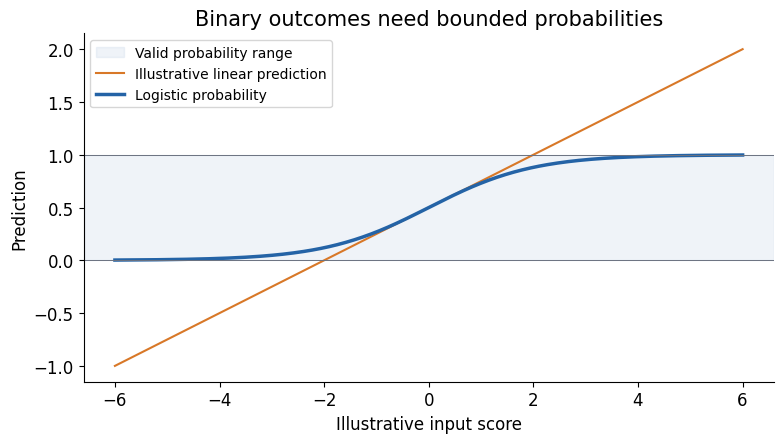

Illustrative linear range: -1.0 to 2.0


In [5]:
z_grid = np.linspace(-6, 6, 300)
linear_demo = 0.5 + 0.25*z_grid
fig, ax = plt.subplots()
ax.axhspan(0, 1, color=BLUE, alpha=0.07, label='Valid probability range')
ax.plot(z_grid, linear_demo, color=ORANGE, label='Illustrative linear prediction')
ax.plot(z_grid, expit(z_grid), color=BLUE, linewidth=2.5, label='Logistic probability')
ax.axhline(0, color=GRAY, linewidth=0.7); ax.axhline(1, color=GRAY, linewidth=0.7)
ax.set(xlabel='Illustrative input score', ylabel='Prediction', title='Binary outcomes need bounded probabilities')
ax.legend(); save_figure(fig, '01_linear_vs_logistic.png')
print(f'Illustrative linear range: {linear_demo.min():.1f} to {linear_demo.max():.1f}')

Im gezeigten Beispiel reicht die Gerade von −1 bis 2; die logistische Kurve bleibt zwischen 0 und 1.
Das macht LogReg für Wahrscheinlichkeiten eines binären Labels geeignet. Es garantiert jedoch noch keine gut kalibrierten Wahrscheinlichkeiten.

## Chapter 2 — Linear predictor and sigmoid

Vereinfacht ergibt sich aus zehn Eingabemerkmalen \(z=\beta_0+\beta_1x_1+\dots+\beta_{10}x_{10}\).
**Im tatsächlichen Modell** erzeugt One-Hot-Encoding zusätzliche Spalten; korrekt ist deshalb
\(z=\beta_0+\sum_{j=1}^{m}\beta_j\tilde x_j\) mit den transformierten Merkmalen \(\tilde x_j\).
Die Sigmoid-Funktion liefert \(P(job\_change=1\mid X)=1/(1+e^{-z})\).

Wir fitten die Basispipeline ausschließlich auf Trainingsdaten. Eine fest gewählte **erste Trainingsperson**
zeigt die Rechnung; ihr Ergebnis ist eine In-Sample-Illustration, kein Leistungsnachweis.

,city_development_index,training_hours,relevant_experience,education_level,experience,last_new_job,enrolled_university,major_discipline,company_size,company_type
17855,0.624023,90.0,1.0,Graduate,10,1,no_enrollment,STEM,50-99,Pvt Ltd


,Value
Intercept,-0.869460
Sum of feature contributions,0.239697
Linear score,-0.629763
Predicted probability,0.347564


Ten original inputs become 32 encoded features.


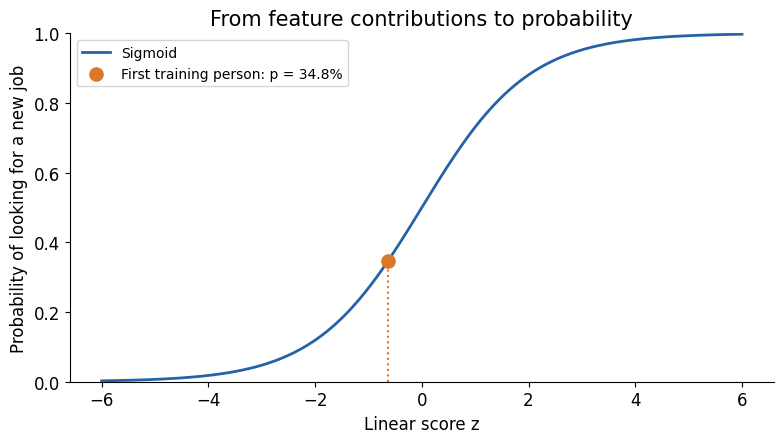

The model assigns this training person a **34.8%** probability of the positive label. This is a model estimate of current job-search intention, not a prediction that the person will actually leave. The feature contributions add exactly to the linear score; they describe the model, not causal effects.

In [6]:
baseline = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier', LogisticRegression(C=1, max_iter=2000)),
])
model = clone(baseline).fit(X_train, y_train)
person = X_train.iloc[[0]]
prep = model.named_steps['preprocessor']
classifier = model.named_steps['classifier']
transformed = prep.transform(person)[0]
contributions = transformed * classifier.coef_[0]
intercept = float(classifier.intercept_[0])
person_score = intercept + contributions.sum()
person_probability = expit(person_score)
assert np.isclose(person_probability, model.predict_proba(person)[0, 1])
display(person)
display(pd.DataFrame({'Value': [intercept, contributions.sum(), person_score, person_probability]},
    index=['Intercept', 'Sum of feature contributions', 'Linear score', 'Predicted probability']))
print(f'Ten original inputs become {len(transformed)} encoded features.')

fig, ax = plt.subplots()
ax.plot(z_grid, expit(z_grid), color=BLUE, linewidth=2, label='Sigmoid')
ax.scatter(person_score, person_probability, color=ORANGE, s=90, zorder=3,
           label=f'First training person: p = {person_probability:.1%}')
ax.vlines(person_score, 0, person_probability, color=ORANGE, linestyles=':')
ax.set(xlabel='Linear score z', ylabel='Probability of looking for a new job',
       title='From feature contributions to probability', ylim=(0, 1))
ax.legend(); save_figure(fig, '02_sigmoid_actual_example.png')
display(Markdown(f'The model assigns this training person a **{person_probability:.1%}** probability of the positive label. '
    'This is a model estimate of current job-search intention, not a prediction that the person will actually leave. '
    'The feature contributions add exactly to the linear score; they describe the model, not causal effects.'))

## Chapter 3 — Binary cross-entropy and maximum likelihood

Für y=1 soll p groß sein; für y=0 soll 1−p groß sein. Der mittlere Verlust lautet
\[BCE=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)].\]
Selbstsichere falsche Vorhersagen erhalten eine hohe Strafe.
Unter unabhängigen Bernoulli-Beobachtungen ist die Likelihood
\(L=\prod_i p_i^{y_i}(1-p_i)^{1-y_i}\): die Wahrscheinlichkeit der beobachteten Labels als Funktion der Parameter.
**Log-Likelihood maximieren entspricht BCE minimieren**, denn \(BCE=-\log(L)/n\).

Die rechte Grafik verwendet ausdrücklich **illustrative Labels [0, 1, 1]** und eine gemeinsame Wahrscheinlichkeit q
für alle drei Fälle. Das ist nur eine Lernillustration, nicht unser Modell mit zehn Merkmalen.
Scikit-learn nutzt zusätzlich L2-Regularisierung: große Gewichte werden bestraft. Wir schätzen somit
penalisiertes Maximum Likelihood, nicht reine unregularisierte MLE; ein eigener Optimierer ist nicht nötig.

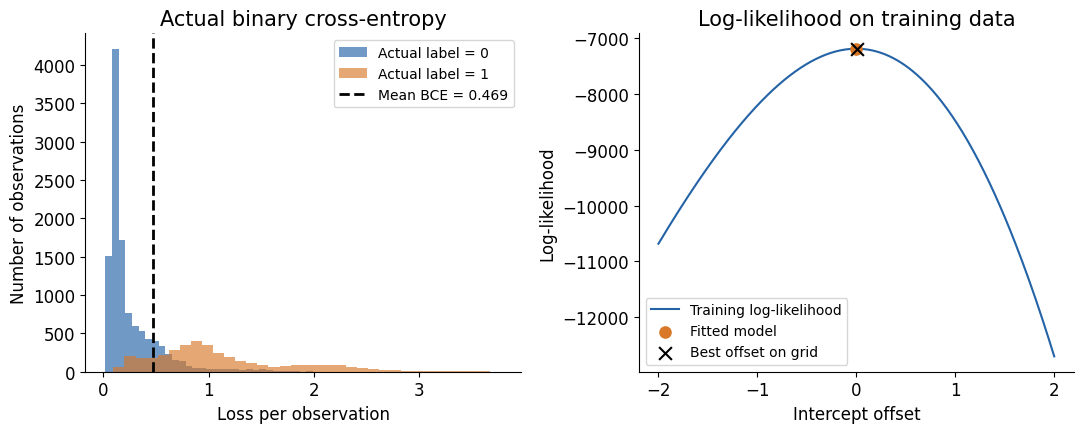

Training observations: 15,326
Actual training BCE: 0.4690
Actual training log-likelihood: -7188.65
Best intercept offset on grid: 0.007
Highest log-likelihood on grid: -7188.70


In [7]:
# Chapter 3: Binary Cross-Entropy & Maximum Likelihood
# Both plots use actual training data and fitted model predictions.

y_actual = np.asarray(y_train).astype(int)
p_pred = model.predict_proba(X_train)[:, 1]

# Avoid log(0)
eps = 1e-15
p_pred = np.clip(p_pred, eps, 1 - eps)

# --------------------------------------------------
# 1. Actual Binary Cross-Entropy
# --------------------------------------------------

individual_loss = -(
    y_actual * np.log(p_pred)
    + (1 - y_actual) * np.log(1 - p_pred)
)

mean_bce = individual_loss.mean()

# --------------------------------------------------
# 2. Actual Log-Likelihood
# Vary the intercept offset while keeping all
# other fitted model parameters unchanged.
# --------------------------------------------------

log_odds = np.log(p_pred / (1 - p_pred))
offset_grid = np.linspace(-2, 2, 300)

log_likelihoods = []

for offset in offset_grid:
    adjusted_log_odds = log_odds + offset

    # Stable calculation of log-likelihood
    ll = np.sum(
        y_actual * adjusted_log_odds
        - np.logaddexp(0, adjusted_log_odds)
    )

    log_likelihoods.append(ll)

log_likelihoods = np.array(log_likelihoods)

best_idx = np.argmax(log_likelihoods)
best_offset = offset_grid[best_idx]
best_ll = log_likelihoods[best_idx]

actual_ll = np.sum(
    y_actual * log_odds
    - np.logaddexp(0, log_odds)
)

# --------------------------------------------------
# 3. Visualization
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: Actual BCE distribution
axes[0].hist(
    individual_loss[y_actual == 0],
    bins=35,
    alpha=0.65,
    color=BLUE,
    label='Actual label = 0'
)

axes[0].hist(
    individual_loss[y_actual == 1],
    bins=35,
    alpha=0.65,
    color=ORANGE,
    label='Actual label = 1'
)

axes[0].axvline(
    mean_bce,
    color='black',
    linestyle='--',
    linewidth=2,
    label=f'Mean BCE = {mean_bce:.3f}'
)

axes[0].set(
    title='Actual binary cross-entropy',
    xlabel='Loss per observation',
    ylabel='Number of observations'
)

axes[0].legend()

# Right: Actual log-likelihood profile
axes[1].plot(
    offset_grid,
    log_likelihoods,
    color=BLUE,
    label='Training log-likelihood'
)

axes[1].scatter(
    0,
    actual_ll,
    color=ORANGE,
    s=65,
    zorder=5,
    label='Fitted model'
)

axes[1].scatter(
    best_offset,
    best_ll,
    color='black',
    marker='x',
    s=85,
    zorder=6,
    label='Best offset on grid'
)

axes[1].set(
    title='Log-likelihood on training data',
    xlabel='Intercept offset',
    ylabel='Log-likelihood'
)

axes[1].legend()

plt.tight_layout()

save_figure(fig, '03_bce_and_likelihood.png')

# --------------------------------------------------
# 4. Actual results
# --------------------------------------------------

print(f'Training observations: {len(y_actual):,}')
print(f'Actual training BCE: {mean_bce:.4f}')
print(f'Actual training log-likelihood: {actual_ll:.2f}')
print(f'Best intercept offset on grid: {best_offset:.3f}')
print(f'Highest log-likelihood on grid: {best_ll:.2f}')

Für ein positives Label steigt der Verlust stark, wenn die vorhergesagte Wahrscheinlichkeit nahe 0 liegt.
Im vereinfachten Drei-Personen-Beispiel maximiert q=2/3 die Likelihood und minimiert zugleich die BCE.
Die echte Trainings-BCE beschreibt die Anpassung an bekannte Fälle; die unabhängige Bewertung folgt erst später.

## Chapter 4 — Stratified 5-fold cross-validation

Wir teilen **nur die Trainingsdatei** in fünf Teile mit ähnlichen Klassenanteilen.
Jede vollständige Pipeline wird auf vier Teilen neu gelernt und auf dem fünften validiert.
Fünf F1-Werte bei Schwelle 0,5 zeigen, wie empfindlich das Ergebnis gegenüber der Aufteilung ist.
Wir berichten Mittelwert und Stichproben-Standardabweichung (ddof=1); die Streuung ist kein Konfidenzintervall.

Nebenbei speichern wir Out-of-Fold-Wahrscheinlichkeiten (OOF): Jede Zeile wird von einem Modell vorhergesagt,
das diese Zeile nicht trainiert hat. Damit legen wir **vor der Testauswertung** die Kostenschwelle für Kapitel 8 fest.

,Fold,F1
0,1,0.3577
1,2,0.3681
2,3,0.3776
3,4,0.3604
4,5,0.3605


Mean F1 = 0.3649; SD = 0.0081
Threshold frozen from training OOF data: 0.885


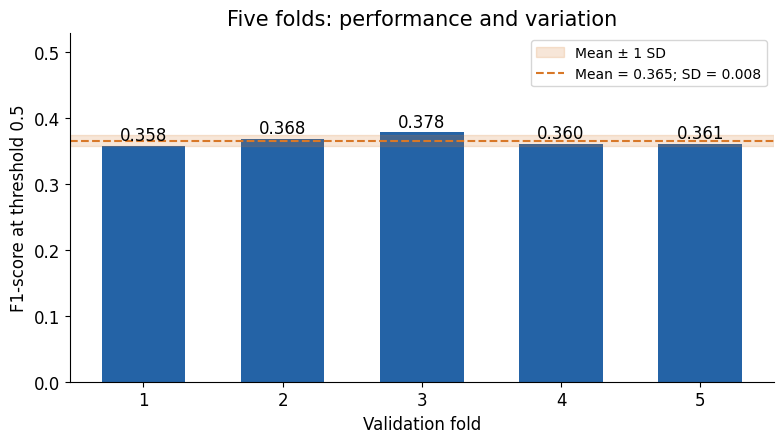

Across five folds, F1 is **0.365 ± 0.008** (sample SD). This describes variation within the supplied training sample, not uncertainty under future data shifts. Preprocessing is refitted inside every fold; the separate test set is excluded.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probability = np.full(len(y_train), np.nan)
fold_f1 = []
for fit_idx, val_idx in cv.split(X_train, y_train):
    fold_model = clone(baseline)
    fold_model.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    p = fold_model.predict_proba(X_train.iloc[val_idx])[:, 1]
    oof_probability[val_idx] = p
    fold_f1.append(f1_score(y_train.iloc[val_idx], p >= 0.5, zero_division=0))
assert np.isfinite(oof_probability).all()
fold_f1 = np.array(fold_f1)
mean_f1, sd_f1 = fold_f1.mean(), fold_f1.std(ddof=1)
display(pd.DataFrame({'Fold': range(1, 6), 'F1': fold_f1}).round(4))
print(f'Mean F1 = {mean_f1:.4f}; SD = {sd_f1:.4f}')

# Hypothetical error costs, fixed before consulting test performance.
COST_FP, COST_FN = 300, 100
threshold_grid = np.linspace(0, 1, 201)
validation_cost = []
for threshold in threshold_grid:
    pred = oof_probability >= threshold
    fp = np.sum((y_train.to_numpy() == 0) & pred)
    fn = np.sum((y_train.to_numpy() == 1) & ~pred)
    validation_cost.append(COST_FP*fp + COST_FN*fn)
validation_cost = np.array(validation_cost)
# Fixed tie-break: choose the highest threshold among equal minima.
best_index = np.flatnonzero(validation_cost == validation_cost.min())[-1]
selected_threshold = float(threshold_grid[best_index])
print(f'Threshold frozen from training OOF data: {selected_threshold:.3f}')

fig, ax = plt.subplots()
ax.bar(range(1, 6), fold_f1, color=BLUE, width=0.6)
ax.axhspan(mean_f1-sd_f1, mean_f1+sd_f1, color=ORANGE, alpha=0.18, label='Mean ± 1 SD')
ax.axhline(mean_f1, color=ORANGE, linestyle='--', label=f'Mean = {mean_f1:.3f}; SD = {sd_f1:.3f}')
for fold, value in enumerate(fold_f1, 1):
    ax.text(fold, value+0.008, f'{value:.3f}', ha='center')
ax.set(xlabel='Validation fold', ylabel='F1-score at threshold 0.5', title='Five folds: performance and variation',
       xticks=range(1, 6), ylim=(0, max(fold_f1)+0.15))
ax.legend(); save_figure(fig, '04_cross_validation_f1.png')
display(Markdown(f'Across five folds, F1 is **{mean_f1:.3f} ± {sd_f1:.3f}** (sample SD). '
    'This describes variation within the supplied training sample, not uncertainty under future data shifts. '
    'Preprocessing is refitted inside every fold; the separate test set is excluded.'))

## Chapter 5 — Confusion matrix on the holdout

Das Basismodell aus Kapitel 2 wurde bereits auf der vollständigen Trainingsdatei fitten gelassen;
wir verwenden exakt dieses Modell weiter, ohne erneuten Fit. Parameter und Kostenschwelle stehen jetzt fest.
Die Testwahrscheinlichkeiten und beide Entscheidungssätze werden einmal berechnet und in Kapitel 5–8 nur ausgelesen.

Die Matrix zeigt zunächst die Standardschwelle **0,5**. Zeilen sind tatsächliche Labels, Spalten vorhergesagte Labels.
Positiv bedeutet „sucht aktuell einen neuen Job“.

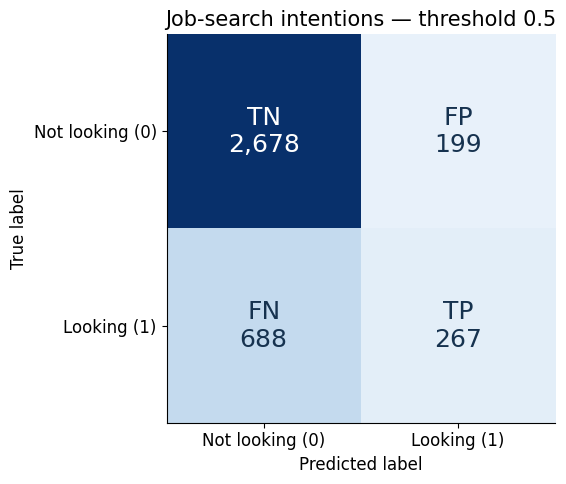

,TN,FP,FN,TP
Rule,,,,
Baseline,2678,199,688,267


**TP=267** people looking for a job are correctly identified; **TN=2678** people not looking are correctly classified. **FP=199** are false alarms, while **FN=688** job seekers are missed.

In [9]:
test_probability = model.predict_proba(X_test)[:, 1]
test_predictions = {'Baseline': (test_probability >= 0.5).astype(int),
                    'Cost-based': (test_probability >= selected_threshold).astype(int)}
evaluation_rows = []
for name, prediction in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
    evaluation_rows.append({'Rule': name,
        'Threshold': 0.5 if name == 'Baseline' else selected_threshold,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Precision': precision_score(y_test, prediction, zero_division=0),
        'Recall': recall_score(y_test, prediction, zero_division=0),
        'F1': f1_score(y_test, prediction, zero_division=0),
        'Accuracy': accuracy_score(y_test, prediction),
        'Total cost': COST_FP*fp + COST_FN*fn})
test_results = pd.DataFrame(evaluation_rows).set_index('Rule')
baseline_results = test_results.loc['Baseline']
cm = confusion_matrix(y_test, test_predictions['Baseline'], labels=[0, 1])
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(cm, cmap='Blues', vmin=0)
names = [['TN', 'FP'], ['FN', 'TP']]
for row in range(2):
    for col in range(2):
        ax.text(col, row, f'{names[row][col]}\n{cm[row, col]:,}', ha='center', va='center',
                fontsize=18, color='white' if cm[row, col] > cm.max()/2 else '#16324F')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Not looking (0)', 'Looking (1)'],
       yticklabels=['Not looking (0)', 'Looking (1)'], xlabel='Predicted label', ylabel='True label',
       title='Job-search intentions — threshold 0.5')
save_figure(fig, '05_confusion_matrix.png')
display(test_results.loc[['Baseline'], ['TN', 'FP', 'FN', 'TP']].astype(int))
display(Markdown(f'**TP={int(baseline_results.TP)}** people looking for a job are correctly identified; '
    f'**TN={int(baseline_results.TN)}** people not looking are correctly classified. '
    f'**FP={int(baseline_results.FP)}** are false alarms, while **FN={int(baseline_results.FN)}** job seekers are missed.'))

## Chapter 6 — Precision, recall and F1-score

**Precision = TP/(TP+FP):** Wie viele der markierten Personen suchen wirklich?
**Recall = TP/(TP+FN):** Wie viele der tatsächlich Suchenden finden wir?
**F1 = 2PR/(P+R):** harmonisches Mittel; hoch, wenn beide Kennzahlen hoch sind.
Diese Kennzahlen beziehen sich auf das positive Label und die Schwelle **0,5**; bei einem Nullnenner berichten wir 0.

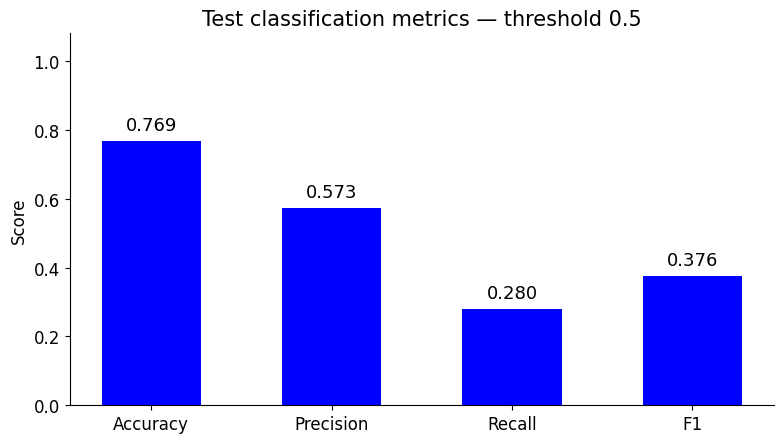

,Test score
Accuracy,0.7685
Precision,0.5730
Recall,0.2796
F1,0.3758


Overall, **76.9%** of predictions are correct. Of those flagged, **57.3%** are actually looking for a job. The model finds **28.0%** of all job seekers, so it misses **72.0%** at threshold 0.5. Lowering the threshold can improve recall but usually produces more false alarms.

In [10]:
metric_values = baseline_results[['Accuracy', 'Precision', 'Recall', 'F1']]

fig, ax = plt.subplots()
bars = ax.bar(
    metric_values.index,
    metric_values.values,
    color="blue",
    width=0.55
)
ax.bar_label(
    bars,
    labels=[f'{value:.3f}' for value in metric_values.values],
    padding=5,
    fontsize=13
)
ax.set(
    ylabel='Score',
    ylim=(0, 1.08),
    title='Test classification metrics — threshold 0.5'
)
save_figure(fig, '06_accuracy_precision_recall_f1.png')

display(metric_values.to_frame('Test score').round(4))
display(Markdown(
    f'Overall, **{baseline_results.Accuracy:.1%}** of predictions are correct. '
    f'Of those flagged, **{baseline_results.Precision:.1%}** are actually looking for a job. '
    f'The model finds **{baseline_results.Recall:.1%}** of all job seekers, so it misses '
    f'**{1-baseline_results.Recall:.1%}** at threshold 0.5. '
    'Lowering the threshold can improve recall but usually produces more false alarms.'
))

## Chapter 7 — ROC curve and AUC

Die **True Positive Rate** ist Recall. Die **False Positive Rate = FP/(FP+TN)** misst den Anteil der
nicht suchenden Personen, die fälschlich markiert werden. Die ROC verbindet diese Werte über alle Schwellen.
Die **AUC** bewertet die Rangordnung: 0,5 entspricht Zufallsranking, 1 perfekter Trennung.
Sie beurteilt weder eine einzelne Schwelle noch die Kalibrierung der Wahrscheinlichkeiten.

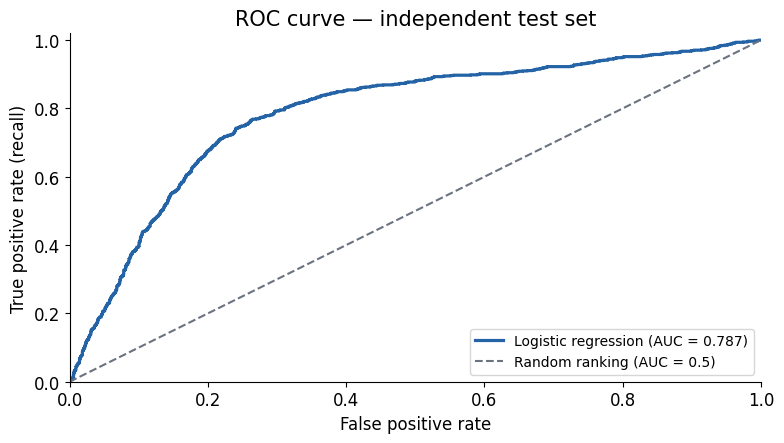

Test ROC-AUC: 0.7872


An AUC of **0.787** means a randomly chosen job seeker receives a higher score than a randomly chosen non-seeker in approximately **78.7%** of pairs (ties count half). Unlike precision, recall and F1 at 0.5, AUC summarizes ranking across thresholds. A different decision threshold leaves this AUC unchanged.

In [11]:
auc = roc_auc_score(y_test, test_probability)
fpr, tpr, _ = roc_curve(y_test, test_probability)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, color=BLUE, linewidth=2.3, label=f'Logistic regression (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], '--', color=GRAY, label='Random ranking (AUC = 0.5)')
ax.set(xlabel='False positive rate', ylabel='True positive rate (recall)',
       title='ROC curve — independent test set', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower right'); save_figure(fig, '07_roc_auc.png')
print(f'Test ROC-AUC: {auc:.4f}')
display(Markdown(f'An AUC of **{auc:.3f}** means a randomly chosen job seeker receives a higher score '
    f'than a randomly chosen non-seeker in approximately **{auc:.1%}** of pairs (ties count half). '
    'Unlike precision, recall and F1 at 0.5, AUC summarizes ranking across thresholds. '
    'A different decision threshold leaves this AUC unchanged.'))

## Chapter 8 — Cost-based threshold and conclusions

Ein FP kann unnötige Ansprache auslösen, ein FN eine Gelegenheit zur Unterstützung übersehen.
**Hypothetische Fehlerkosten:** FP = 100 Einheiten, FN = 500; TP und TN = 0.
Das sind ausdrücklich Annahmen, keine gemessenen Geschäftskosten oder nachgewiesenen Interventionseffekte.
\[\text{Total cost}=100\cdot FP+500\cdot FN.\]

In Kapitel 4 wurde auf Trainings-OOF-Prognosen ein festes Raster (0 bis 1, Schritt 0,005) verglichen.
Die Schwelle mit den geringsten Gesamtkosten wurde eingefroren; bei Gleichstand gewinnt die höhere Schwelle.
Die folgende Kurve zeigt **beobachtete Validierungsfehlerkosten als Schätzung** künftiger Kosten.
Ihr Minimum ist wegen der Schwellenwahl optimistisch, keine unabhängige Leistungsschätzung.

Bei kalibrierten Wahrscheinlichkeiten und dieser Kostenstruktur wäre theoretisch
\(t=C_{FP}/(C_{FP}+C_{FN})=1/6\) angemessen: Klasse 1 kostet erwartet \(100(1-p)\), Klasse 0 \(500p\).
Da wir Kalibrierung nicht nachgewiesen haben, verwenden wir die einfache OOF-Kostenentscheidung.
Die Testlabels werden weder für die Kurve noch für die Auswahl verwendet.

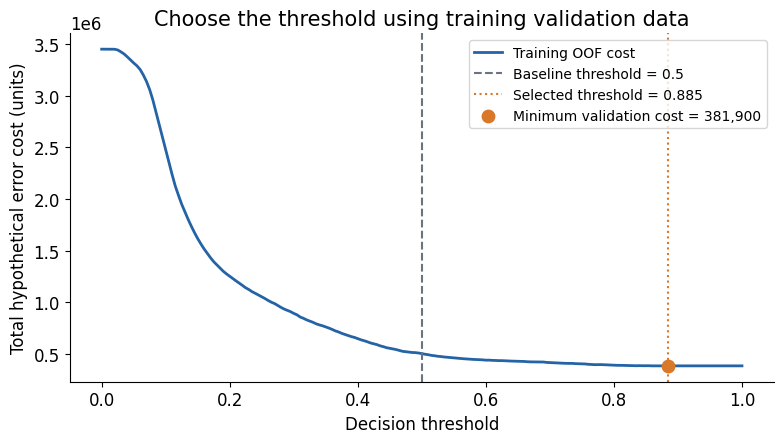

Selected threshold: 0.885; minimum OOF cost: 381,900


,Threshold,TN,FP,FN,TP,Precision,Recall,F1,Accuracy,Total cost
Rule,,,,,,,,,,
Baseline,0.500,2678,199,688,267,0.573,0.280,0.376,0.769,128500
Cost-based,0.885,2877,0,954,1,1.000,0.001,0.002,0.751,95400


On the held-out test data, recall changes from **0.280** to **0.001**, and precision from **0.573** to **1.000**. False alarms change from **199** to **0**, while missed seekers change from **688** to **954**. Total hypothetical test cost changes from **128,500** to **95,400** units under the assumed cost structure.

# Main findings — Job Change Intentions

- One fixed logistic regression with the original preprocessing; 15,326 training and 3,832 test cases.
- Five-fold training CV: F1 = 0.3649 ± 0.0081 (sample SD, threshold 0.5).
- Test AUC = 0.7872; baseline precision = 0.5730, recall = 0.2796, F1 = 0.3758.
- Training OOF selection yields threshold 0.885, assuming FP costs 300 and FN costs 100 units.
- At that threshold, test precision = 1.0000, recall = 0.0010, F1 = 0.0021.
- Hypothetical test costs: 128,500 → 95,400 units; FP: 199 → 0; FN: 688 → 954.

The model estimates current job-search intention, not actual future departures. The higher decision threshold reduces false alarms but may miss more job seekers. It minimizes the hypothetical error cost on the training OOF predictions under the assumed cost structure.. Costs and feature availability are assumptions; these results do not prove calibration, fairness, causality, or the benefit of an intervention. Earlier preprocessing inside the supplied PKL files cannot be audited here. Generalization to future populations needs further validation.

Eight 300-dpi English figures are saved in figures/. No slide deck was created.


In [12]:
#COST_FP, COST_FN = 300, 100

minimum_cost = validation_cost[best_index]
fig, ax = plt.subplots()
ax.plot(threshold_grid, validation_cost, color=BLUE, linewidth=2, label='Training OOF cost')
ax.axvline(0.5, color=GRAY, linestyle='--', label='Baseline threshold = 0.5')
ax.axvline(selected_threshold, color=ORANGE, linestyle=':',
           label=f'Selected threshold = {selected_threshold:.3f}')
ax.scatter(selected_threshold, minimum_cost, color=ORANGE, s=80, zorder=3,
           label=f'Minimum validation cost = {minimum_cost:,.0f}')
ax.set(xlabel='Decision threshold', ylabel='Total hypothetical error cost (units)',
       title='Choose the threshold using training validation data')
ax.legend(); save_figure(fig, '08_validation_cost_threshold.png')
print(f'Selected threshold: {selected_threshold:.3f}; minimum OOF cost: {minimum_cost:,.0f}')
display(test_results.round(3))
changed = test_results.loc['Cost-based']
display(Markdown(f'On the held-out test data, recall changes from **{baseline_results.Recall:.3f}** '
    f'to **{changed.Recall:.3f}**, and precision from **{baseline_results.Precision:.3f}** '
    f'to **{changed.Precision:.3f}**. '
    f'False alarms change from **{int(baseline_results.FP)}** to **{int(changed.FP)}**, '
    f'while missed seekers change from **{int(baseline_results.FN)}** to **{int(changed.FN)}**. '
    f'Total hypothetical test cost changes from **{baseline_results["Total cost"]:,.0f}** '
    f'to **{changed["Total cost"]:,.0f}** units under the assumed cost structure.'))

summary = f"""# Main findings — Job Change Intentions

- One fixed logistic regression with the original preprocessing; {len(y_train):,} training and {len(y_test):,} test cases.
- Five-fold training CV: F1 = {mean_f1:.4f} ± {sd_f1:.4f} (sample SD, threshold 0.5).
- Test AUC = {auc:.4f}; baseline precision = {baseline_results.Precision:.4f}, recall = {baseline_results.Recall:.4f}, F1 = {baseline_results.F1:.4f}.
- Training OOF selection yields threshold {selected_threshold:.3f}, assuming FP costs 300 and FN costs 100 units.
- At that threshold, test precision = {changed.Precision:.4f}, recall = {changed.Recall:.4f}, F1 = {changed.F1:.4f}.
- Hypothetical test costs: {baseline_results['Total cost']:,.0f} → {changed['Total cost']:,.0f} units; FP: {int(baseline_results.FP)} → {int(changed.FP)}; FN: {int(baseline_results.FN)} → {int(changed.FN)}.

The model estimates current job-search intention, not actual future departures. The higher decision threshold reduces false alarms but may miss more job seekers. It minimizes the hypothetical error cost on the training OOF predictions under the assumed cost structure.. Costs and feature availability are assumptions; these results do not prove calibration, fairness, causality, or the benefit of an intervention. Earlier preprocessing inside the supplied PKL files cannot be audited here. Generalization to future populations needs further validation.

Eight 300-dpi English figures are saved in figures/. No slide deck was created.
"""
Path('logistic_regression_job_change_summary.md').write_text(summary, encoding='utf-8')
display(Markdown(summary))

**Praktische Einordnung:** LogReg ist ein verständliches Basismodell, das aus bekannten Merkmalen eine Rangfolge
und Wahrscheinlichkeiten ableitet. Die vorgegebene ordinale Codierung unterstellt Abstände zwischen Kategorien;
korrelierte Merkmale und soziale Proxy-Variablen können die Interpretation beeinflussen.
Die Ergebnisse begründen keine automatischen Personalentscheidungen: Zielbedeutung, verfügbare Merkmale,
Kosten und Übertragbarkeit müssen zum realen Einsatz passen.

**Ausführungsprüfung:** Die Codezellen werden in einem frischen Python-Prozess in Notebook-Reihenfolge geprüft;
die gespeicherten Ergebnisse und PNGs stammen aus den mitgelieferten Daten. Illustrative Werte sind ausdrücklich markiert.

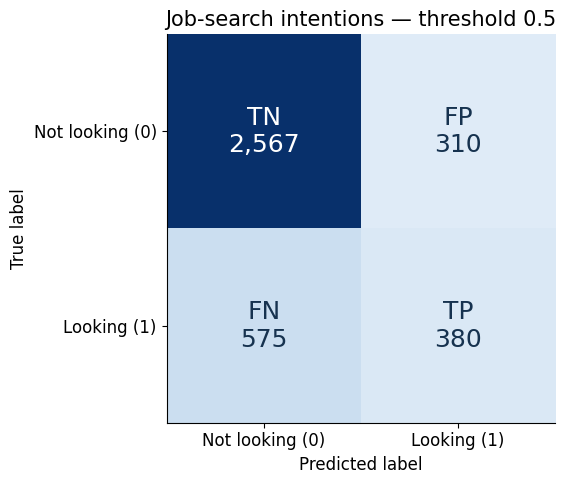

,TN,FP,FN,TP
Rule,,,,
Baseline,2567,310,575,380


**TP=380** people looking for a job are correctly identified; **TN=2567** people not looking are correctly classified. **FP=310** are false alarms, while **FN=575** job seekers are missed.

In [13]:
#Tills Grafik hardcodiert


## hard codiert 
# Fest eingetragene Werte
TN = 2567
FP = 310
FN = 575
TP = 380

test_results = pd.DataFrame(
    [{'Rule': 'Baseline', 'TN': TN, 'FP': FP, 'FN': FN, 'TP': TP}]
).set_index('Rule')

cm = np.array([[TN, FP], [FN, TP]])

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(cm, cmap='Blues', vmin=0)

names = [['TN', 'FP'], ['FN', 'TP']]
for row in range(2):
    for col in range(2):
        ax.text(
            col, row,
            f'{names[row][col]}\n{cm[row, col]:,}',
            ha='center',
            va='center',
            fontsize=18,
            color='white' if cm[row, col] > cm.max() / 2 else '#16324F'
        )

ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=['Not looking (0)', 'Looking (1)'],
    yticklabels=['Not looking (0)', 'Looking (1)'],
    xlabel='Predicted label',
    ylabel='True label',
    title='Job-search intentions — threshold 0.5'
)

save_figure(fig, '05_confusion_matrix.png')

display(test_results[['TN', 'FP', 'FN', 'TP']].astype(int))

display(Markdown(
    f'**TP={TP}** people looking for a job are correctly identified; '
    f'**TN={TN}** people not looking are correctly classified. '
    f'**FP={FP}** are false alarms, while **FN={FN}** job seekers are missed.'
))

# Export Test Wahrscheinlichkeit LogReg

Hier wird eine pickle Datei erstellt mit den Werten zum Vergleich der Modelle und zur Visualisierung

In [14]:
pd.DataFrame({
    "student_id": test_data["student_id"].values,
    "y_true": y_test.values,
    "proba": test_probability,
}).to_pickle("pred_logreg.pkl")